# Baseline Atlas-DeePC

This baseline notebook uses **OSQP** and **$\lambda_g=0$**, 48 physical-configuration
charts, rank-60 uncentered linear subspaces, and iterative N=10 terminal-reference
augmentation. This notebook compares two algorithms on the same evaluation seeds:

1. **Atlas-DeePC without graph waypoints:** track the selected terminal reference
   from the first control step.
2. **Atlas-DeePC with graph waypoints:** track the next chart representative until
   the 7 cm terminal-mode latch, then track the selected terminal reference.

All results and videos below use OSQP. The earlier solver-comparison notebook is
archived; no comparison with another solver is needed to run this notebook.

**Scope:** both algorithms retain graph-route-cost selection of the N=10 terminal
candidates. "Without graph waypoints" does not mean all graph information is
removed. Only the use of intermediate waypoint references changes. Because the
closed-loop trajectories differ, their subsequently selected terminal configurations
can differ too, despite using the same selection rule and candidate pool.

There is no contextual rescue, fitted dynamics, IK controller, added offline data,
or measurement noise. Every successful solve supplies an action through DeePC.
Unsolved QPs, if any, are reported rather than omitted. The old $\lambda_g=0.05$
notebook and its results remain archived; none of its outcome labels is reused here.


In [1]:
import json
import os
import sys
from pathlib import Path
from dataclasses import asdict
os.environ.setdefault("MPLCONFIGDIR", "/tmp/atlas_deepc_mpl")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
get_ipython().run_line_magic("matplotlib", "inline")
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/baseline_atlas_deepc.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import baseline_atlas_deepc as baseline
import routed_deepc_experiment as experiment
import baseline_osqp_comparison as comparison
from baseline_osqp_benchmark import run_fresh_panel
from baseline_waypoint_comparison import METHODS
DATA_PATH, ATLAS_PATH = baseline.DATA_PATH, baseline.ATLAS_PATH
RESULT_ROOT = comparison.RESULT_ROOT  # Or Path("...") to reopen a completed local benchmark.
EVALUATION_SEEDS = list(range(211, 1211))  # Stop is exclusive; edit this range.
RUN_EVALUATION = False  # True: measure fresh local timings; False: view saved OSQP results.
WORKERS = 1
SOLVER = "OSQP"
assert SOLVER == "OSQP"
assert EVALUATION_SEEDS and len(set(EVALUATION_SEEDS)) == len(EVALUATION_SEEDS)
config = baseline.default_config()
assert config.lam_g == 0
if RUN_EVALUATION:
    RESULT_ROOT = run_fresh_panel(EVALUATION_SEEDS, workers=WORKERS)
    print("FRESH LOCAL OSQP RUN:", RESULT_ROOT)
else:
    print("SAVED OSQP RESULTS: these timings are not new measurements on this computer.")
H = np.load(DATA_PATH, mmap_mode="r")
atlas = experiment.load_atlas(ATLAS_PATH)
COLORS = {"terminal": "#D55E00", "graph": "#0072B2"}
print("Baseline version:", baseline.BASELINE_VERSION)
print("Solver:", SOLVER)
print(f"Evaluation: {len(EVALUATION_SEEDS)} paired seeds, {min(EVALUATION_SEEDS)}--{max(EVALUATION_SEEDS)}")


SAVED OSQP RESULTS: these timings are not new measurements on this computer.
Baseline version: linear_iterative_n10_lamg0_v2
Solver: OSQP
Evaluation: 1000 paired seeds, 211--1210


## 1. Linear-Subspace DeePC and References

For each chart, collect its complete offline columns $X_k$ and retain the leading
60 left singular vectors **without mean subtraction**. The QP uses the current
chart's cached basis $B_k$:

$$\begin{bmatrix}u_{\rm ini}\\u\\y_{\rm ini}+\sigma\\y\end{bmatrix}=B_k g.$$

There is no affine offset, sum-to-one constraint, or coefficient-norm penalty.
The empirical coefficient bounds remain in place. All $U_p,U_f,Y_p,Y_f$ rows are
retained. Q, R, past-output slack and input-smoothness penalties remain unchanged:

$$Q=\operatorname{diag}(5000I_4,20I_2,10^5I_2,5000I_2),\quad R=10^{-4}I_2,$$
$$\lambda_g=0,\quad\lambda_{\rm ini}=10^5,\quad\lambda_{\Delta u}=5.$$

Both methods use two past steps, a ten-step prediction horizon, input limits
$[-1,1]$, and 320 control steps. The additional terminal cost is zero.

OSQP uses a 10,000-iteration limit, absolute and relative tolerances 1e-5, and
polishing through the installed CVXPY adapter. Each step constructs a fresh QP;
there is no cross-step factorization cache or warm start. No alternative solver
is used if a QP fails. The existing zero-action behavior is retained for unsolved
steps, which remain in the reported outcomes.

### Common Iterative Terminal Reference

1. Once the target is known, find the ten eligible offline configurations with
   closest fingertips. Exclude source episodes with original targets within 6 cm
   of the online target. Deduplicate candidates by chart.
2. Each step, locate the current chart and select the candidate chart with minimum
   directed route cost. Ties use fingertip error and source index.
3. The selected candidate supplies the posture; velocities are set to zero and
   fingertip coordinates to the requested target. Candidate selection continues
   throughout both rollouts, including after the waypoint method's 7 cm latch.

The one-time candidate search is shared in definition, not an online trajectory
retrieval. The graph provides references, never control actions.


In [2]:
from threadpoolctl import threadpool_limits
with threadpool_limits(limits=1):
    controller = baseline.BaselineAtlasDeePC(H, atlas, config)
assert len(controller.matrix_cache) == 48
assert all(not np.any(m["offset"]) and m["basis"].shape == (144, 60)
           and "g_sum" not in m for m, _ in controller.matrix_cache.values())
display(pd.Series({"charts": config.clusters, "linear-subspace rank": config.svd_rank,
    "solver": SOLVER, "lambda_g": config.lam_g, "candidate count": baseline.CANDIDATE_COUNT,
    "DeePC matrix": "current chart only", "terminal-reference selection": "iterative minimum route cost",
    "changed component between methods": "intermediate graph waypoint references only"}))


charts                                                                        48
linear-subspace rank                                                          60
solver                                                                      OSQP
lambda_g                                                                     0.0
candidate count                                                               10
DeePC matrix                                                  current chart only
terminal-reference selection                        iterative minimum route cost
changed component between methods    intermediate graph waypoint references only
dtype: object

## 2. Inspecting the constructed physical-configuration atlas

A chart is defined by K-means on the latest periodic joint configuration

$$
\phi(y_t)=[\cos q_1,\cos q_2,\sin q_1,\sin q_2,\cos(q_1+q_2),\sin(q_1+q_2)].
$$

Inputs, velocities, fingertip coordinates, and the preceding output are not used to assign charts. Each panel below overlays 32 randomly sampled chart members in a shallow color and draws the chart medoid boldly. This is the updated 48-chart version of the configuration-cloud plot.


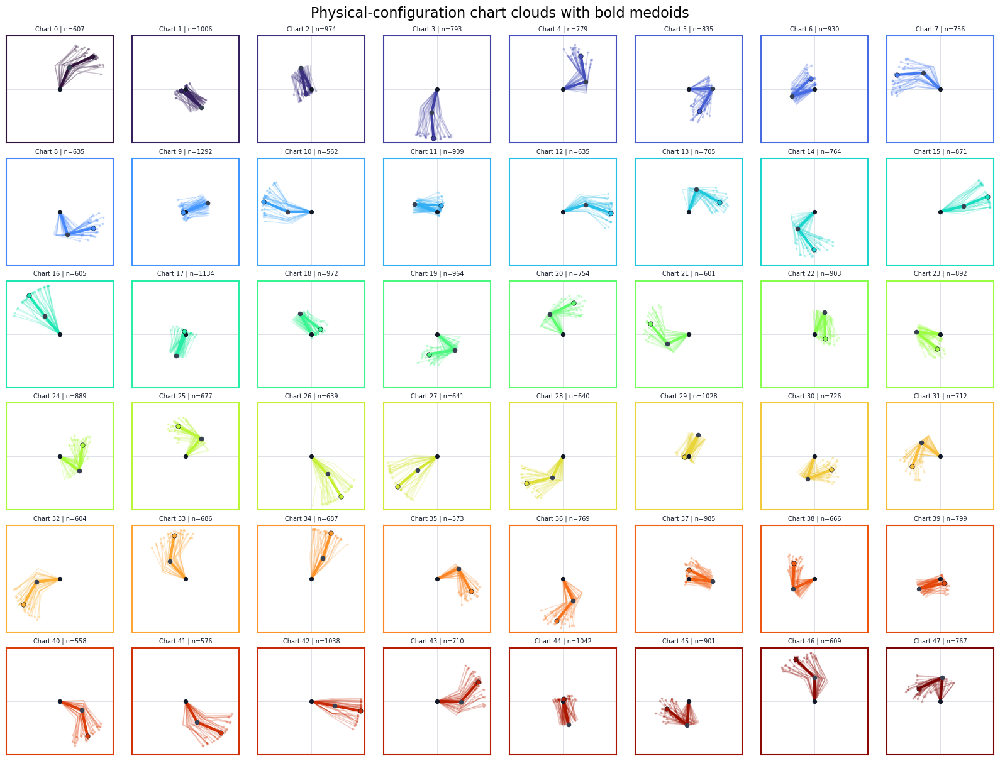

Medoid forward-kinematics consistency: max 0.505 mm
Chart occupancy: min 558, median 760, max 1292 windows


In [3]:
from matplotlib.collections import LineCollection

chart_sizes = np.bincount(atlas["labels"].astype(int), minlength=config.clusters)
medoid_states = np.asarray(atlas["medoid_states"], dtype=float)
chart_colors = plt.cm.turbo(np.linspace(0.0, 1.0, config.clusters))
chart_output_states = H[experiment.pipe.M * experiment.pipe.L:].reshape(
    experiment.pipe.L, experiment.pipe.P, H.shape[1]
)[experiment.pipe.T_INI - 1].T
cloud_members_per_chart = 32
cloud_rng = np.random.default_rng(17)

# Reacher-v5's output geometry is approximately 0.10 m to the elbow and
# 0.11 m from the elbow to the reported fingertip site.
link_1, link_2 = 0.10, 0.11
elbows = link_1 * np.column_stack([medoid_states[:, 0], medoid_states[:, 2]])
fk_fingertips = elbows + link_2 * np.column_stack([medoid_states[:, 8], medoid_states[:, 9]])
stored_fingertips = medoid_states[:, 6:8]
fk_error = np.linalg.norm(fk_fingertips - stored_fingertips, axis=1)

fig, axes = plt.subplots(6, 8, figsize=(16, 12), constrained_layout=True)
for chart_id, ax in enumerate(axes.flat):
    elbow = elbows[chart_id]
    fingertip = stored_fingertips[chart_id]
    color = chart_colors[chart_id]
    member_indices = np.flatnonzero(atlas["labels"] == chart_id)
    sampled_indices = cloud_rng.choice(
        member_indices, size=min(cloud_members_per_chart, member_indices.size), replace=False
    )
    cloud_states = chart_output_states[sampled_indices]
    cloud_elbows = link_1 * np.column_stack([cloud_states[:, 0], cloud_states[:, 2]])
    cloud_fingertips = cloud_states[:, 6:8]
    cloud_segments = np.stack([
        np.zeros_like(cloud_elbows), cloud_elbows, cloud_fingertips
    ], axis=1)
    ax.add_collection(LineCollection(
        cloud_segments, colors=[color], linewidths=1.05, alpha=0.24, zorder=1
    ))
    ax.scatter(cloud_fingertips[:, 0], cloud_fingertips[:, 1], s=7,
               color=color, alpha=0.32, linewidth=0, zorder=1)
    ax.plot([0, elbow[0], fingertip[0]], [0, elbow[1], fingertip[1]],
            color=color, linewidth=3.0, solid_capstyle="round", zorder=3)
    ax.scatter([0], [0], s=18, color="#111827", zorder=3)
    ax.scatter([elbow[0]], [elbow[1]], s=20, color="#374151", zorder=3)
    ax.scatter([fingertip[0]], [fingertip[1]], s=28, color=color,
               edgecolor="#111827", linewidth=0.5, zorder=4)
    ax.axhline(0, color="#d1d5db", linewidth=0.5, zorder=0)
    ax.axvline(0, color="#d1d5db", linewidth=0.5, zorder=0)
    ax.set_xlim(-0.225, 0.225)
    ax.set_ylim(-0.225, 0.225)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"Chart {chart_id} | n={chart_sizes[chart_id]}", fontsize=7, color="#111827")
    for spine in ax.spines.values():
        spine.set_color(color)
        spine.set_linewidth(1.5)
fig.suptitle("Physical-configuration chart clouds with bold medoids", fontsize=16)
medoid_plot_path = RESULT_ROOT / "physical48_chart_configuration_clouds.png"
fig.savefig(medoid_plot_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Medoid forward-kinematics consistency: max {1000 * fk_error.max():.3f} mm")
print(f"Chart occupancy: min {chart_sizes.min()}, median {np.median(chart_sizes):.0f}, max {chart_sizes.max()} windows")


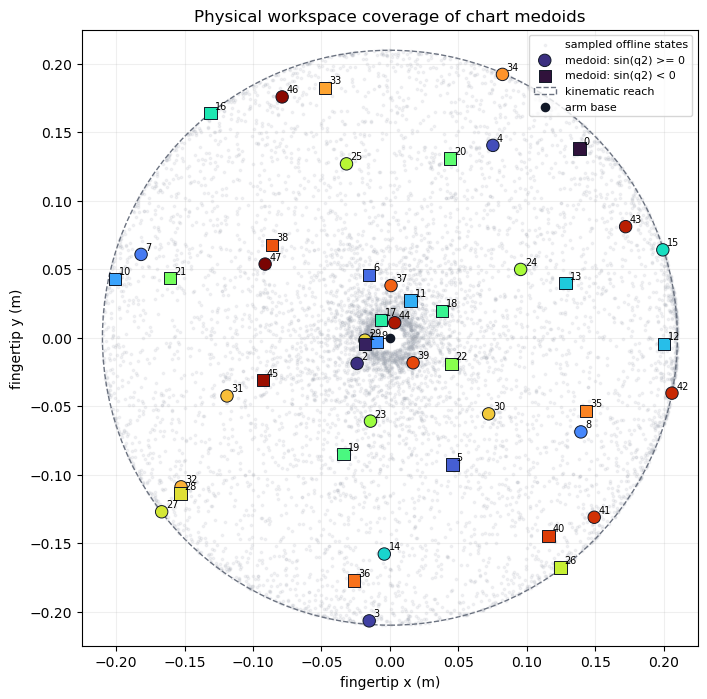

In [4]:
Y_windows = H[experiment.pipe.M * experiment.pipe.L:].reshape(
    experiment.pipe.L, experiment.pipe.P, H.shape[1]
)
offline_fingertips = Y_windows[experiment.pipe.T_INI - 1, 6:8].T
workspace_sample = np.linspace(0, offline_fingertips.shape[0] - 1, 8000, dtype=int)
elbow_up = medoid_states[:, 3] >= 0.0  # sign of sin(q2)

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(offline_fingertips[workspace_sample, 0], offline_fingertips[workspace_sample, 1],
           s=3, color="#9ca3af", alpha=0.12, label="sampled offline states")
for mask, marker, label in [(elbow_up, "o", "medoid: sin(q2) >= 0"),
                            (~elbow_up, "s", "medoid: sin(q2) < 0")]:
    ax.scatter(stored_fingertips[mask, 0], stored_fingertips[mask, 1],
               c=chart_colors[mask], marker=marker, s=80, edgecolor="#111827",
               linewidth=0.7, label=label, zorder=3)
for chart_id, (x, y) in enumerate(stored_fingertips):
    ax.annotate(str(chart_id), (x, y), xytext=(3, 3), textcoords="offset points", fontsize=7)
ax.add_patch(plt.Circle((0, 0), link_1 + link_2, fill=False, linestyle="--",
                        color="#6b7280", linewidth=1, label="kinematic reach"))
ax.scatter([0], [0], color="#111827", s=35, label="arm base", zorder=4)
ax.set_aspect("equal")
ax.set_xlim(-0.225, 0.225)
ax.set_ylim(-0.225, 0.225)
ax.set_xlabel("fingertip x (m)")
ax.set_ylabel("fingertip y (m)")
ax.set_title("Physical workspace coverage of chart medoids")
ax.grid(alpha=0.2)
ax.legend(loc="upper right", fontsize=8)
workspace_plot_path = RESULT_ROOT / "atlas_workspace_coverage.png"
fig.savefig(workspace_plot_path, dpi=160, bbox_inches="tight")
plt.show()

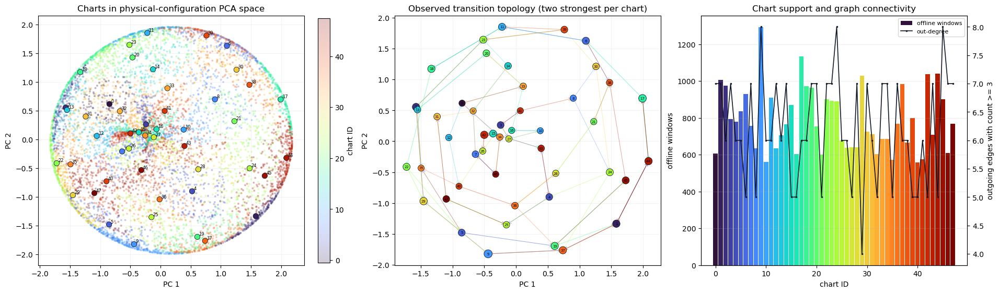

Active clustering coordinates: 6
PCA variance captured: 38.1%
Directed routing edges retained by the controller: 298
Outgoing-degree range: 4 to 8


In [5]:
from sklearn.decomposition import PCA

clustering_features, _, _ = experiment.behavioral_features(
    H,
    config.clustering_input_weight,
    config.clustering_feature_mode,
    config.clustering_configuration_weight,
    config.clustering_velocity_weight,
    config.clustering_fingertip_weight,
)
active_feature_mask = clustering_features.std(axis=0) > 1e-10
gate_features = clustering_features[:, active_feature_mask]
gate_centers = atlas["centers"][:, active_feature_mask]
pca = PCA(n_components=2)
gate_pca = pca.fit_transform(gate_features)
center_pca = pca.transform(gate_centers)
history_sample = np.linspace(0, gate_pca.shape[0] - 1, 8000, dtype=int)
transition_counts = np.asarray(atlas["transition_counts"], dtype=int)
edge_mask = transition_counts >= config.edge_count_threshold
np.fill_diagonal(edge_mask, False)
out_degree = edge_mask.sum(axis=1)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), constrained_layout=True)
scatter = axes[0].scatter(gate_pca[history_sample, 0], gate_pca[history_sample, 1],
                          c=atlas["labels"][history_sample], cmap="turbo",
                          vmin=-0.5, vmax=config.clusters - 0.5, s=4, alpha=0.22)
axes[0].scatter(center_pca[:, 0], center_pca[:, 1], c=chart_colors, s=55,
                edgecolor="#111827", linewidth=0.6)
for chart_id, (x, y) in enumerate(center_pca):
    axes[0].annotate(str(chart_id), (x, y), xytext=(2, 2),
                     textcoords="offset points", fontsize=6)
axes[0].set_title("Charts in physical-configuration PCA space")
axes[0].set_xlabel("PC 1")
axes[0].set_ylabel("PC 2")
axes[0].grid(alpha=0.15)
fig.colorbar(scatter, ax=axes[0], label="chart ID", fraction=0.046)

# Show the two strongest observed outgoing transitions per chart. The router
# itself retains every edge meeting the count threshold.
for source in range(config.clusters):
    destinations = np.flatnonzero(edge_mask[source])
    if destinations.size:
        strongest = destinations[np.argsort(transition_counts[source, destinations])[-2:]]
        for destination in strongest:
            strength = transition_counts[source, destination]
            axes[1].annotate("", xy=center_pca[destination], xytext=center_pca[source],
                             arrowprops=dict(arrowstyle="->", color=chart_colors[source],
                                             alpha=min(0.75, 0.18 + strength / 250),
                                             linewidth=0.7))
node_sizes = 35 + 90 * chart_sizes / chart_sizes.max()
axes[1].scatter(center_pca[:, 0], center_pca[:, 1], c=chart_colors, s=node_sizes,
                edgecolor="#111827", linewidth=0.6, zorder=3)
for chart_id, (x, y) in enumerate(center_pca):
    axes[1].annotate(str(chart_id), (x, y), ha="center", va="center", fontsize=5, zorder=4)
axes[1].set_title("Observed transition topology (two strongest per chart)")
axes[1].set_xlabel("PC 1")
axes[1].set_ylabel("PC 2")
axes[1].grid(alpha=0.15)

chart_ids = np.arange(config.clusters)
axes[2].bar(chart_ids, chart_sizes, color=chart_colors, width=0.9, label="offline windows")
axes[2].set_xlabel("chart ID")
axes[2].set_ylabel("offline windows")
axes[2].set_title("Chart support and graph connectivity")
axes[2].grid(axis="y", alpha=0.2)
degree_axis = axes[2].twinx()
degree_axis.plot(chart_ids, out_degree, color="#111827", linewidth=1.2,
                 marker=".", markersize=3, label="out-degree")
degree_axis.set_ylabel("outgoing edges with count >= 3")
lines_1, labels_1 = axes[2].get_legend_handles_labels()
lines_2, labels_2 = degree_axis.get_legend_handles_labels()
axes[2].legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper right", fontsize=8)

topology_plot_path = RESULT_ROOT / "physical48_atlas_topology.png"
fig.savefig(topology_plot_path, dpi=160, bbox_inches="tight")
plt.show()
print("Active clustering coordinates:", gate_features.shape[1])
print("PCA variance captured:", f"{100 * pca.explained_variance_ratio_.sum():.1f}%")
print("Directed routing edges retained by the controller:", int(edge_mask.sum()))
print("Outgoing-degree range:", int(out_degree.min()), "to", int(out_degree.max()))


### How to read these views

- The shallow arm clouds show posture variation inside each chart, while the bold arm is the medoid. Because assignment uses the current periodic joint configuration, each chart is now directly interpretable as a compact physical-posture neighborhood.
- The workspace plot checks physical coverage and reveals both elbow branches. A medoid is not a target and does not imply that its source trajectory was successful.
- The PCA view is only a two-dimensional projection of the six active configuration coordinates. Overlap in this view does not mean the original chart assignments overlap.
- Node size and support bars show how many complete input-output Hankel columns back each chart. The topology panel draws only two strong outgoing edges per node; online routing uses every observed directed edge with count at least three.


## 3. Paired Results and Fairness

Strict success requires mean fingertip error below 10 mm and maximum error below
20 mm in **both final-30 and final-100 windows**. Every rollout retains all 320
steps. These repeatedly used evaluation seeds are not a new untouched test set.


In [6]:
payload = json.loads((RESULT_ROOT / "summary.json").read_text())
assert payload["version"] == comparison.VERSION
assert payload["signature"]["baseline_version"] == baseline.BASELINE_VERSION
assert payload["signature"]["config"] == asdict(config)
assert payload["signature"]["solver"] == SOLVER == "OSQP"
audit = payload["fairness_audit"]
assert audit["offline_stabilized_episode_count"] == 0
rows_by_mode, records, errors = {}, [], {}
for mode in METHODS:
    by_seed = {int(r["seed"]): r for r in payload["panels"][mode]["results"]}
    missing = sorted(set(EVALUATION_SEEDS)-set(by_seed))
    assert not missing, f"{mode}: missing {len(missing)} requested seeds. Enable RUN_EVALUATION."
    rows_by_mode[mode] = {seed: by_seed[seed] for seed in EVALUATION_SEEDS}
    for seed, row in rows_by_mode[mode].items():
        assert row["baseline_version"] == baseline.BASELINE_VERSION and row["lam_g"] == 0
        assert row["solver"] == SOLVER and row["solver_ablation_version"] == comparison.VERSION
        assert row["reference_mode"] == mode and row["graph_waypoints_enabled"] == (mode == "graph")
        assert row["matrix_geometry"] == "linear" and row["candidate_count"] == 10 and row["steps"] == 320
        assert row["minimum_selected_goal_source_separation"] >= .06
        assert not row["fitted_dynamics_model"] and not row["feedback_fallback"]
        path = RESULT_ROOT / mode / f"seed{seed}_control_results.npz"
        with np.load(path, allow_pickle=True) as trace:
            target = trace["final_goal"].reshape(-1)[6:8]
            np.testing.assert_allclose(trace["distance"], np.linalg.norm(trace["y"][:, 6:8]-target, axis=1))
            error = 1000*trace["distance"]
        errors[mode, seed] = error
        records.append({"mode": mode, "method": METHODS[mode], "seed": seed,
            "strict": bool(row["success_30"] and row["success_100"]),
            "mean_error_mm": 1000*row["mean_last_100"], "minimum_mm": float(error.min()),
            "tail_time_below10_pct": 100*np.mean(error[-100:] < 10),
            "unsolved_qps": row["unsolved_steps"],
            "optimal_inaccurate_qps": row["optimal_inaccurate_steps"]})
for seed in EVALUATION_SEEDS:
    np.testing.assert_array_equal(rows_by_mode["terminal"][seed]["exact_target_xy"], rows_by_mode["graph"][seed]["exact_target_xy"])
frame = pd.DataFrame(records)
summary = pd.DataFrame([{"Method": METHODS[mode], "Successes": int((g:=frame[frame['mode']==mode]).strict.sum()),
    "Trials": len(g), "Success rate (%)": 100*g.strict.mean(),
    "Median final-100 mean (mm)": g.mean_error_mm.median(),
    "P90 final-100 mean (mm)": g.mean_error_mm.quantile(.9),
    "Mean final-100 time below 10 mm (%)": g.tail_time_below10_pct.mean(),
    "Unsolved QPs": int(g.unsolved_qps.sum()),
    "Optimal inaccurate QPs": int(g.optimal_inaccurate_qps.sum())} for mode in METHODS]).set_index("Method")
display(summary.round(3))
display(pd.Series({"offline seed range": str(audit["data_seed_range"]),
    "stabilized offline episodes": audit["offline_stabilized_episode_count"],
    "minimum selected source-target separation (m)": min(r["minimum_selected_goal_source_separation"] for rows in rows_by_mode.values() for r in rows.values()),
    "lambda_g, both methods": config.lam_g, "per-step full-library trajectory retrieval": "none"}))
paired = frame.pivot(index="seed", columns="mode", values="strict")
graph_only = paired.index[paired.graph & ~paired.terminal].tolist()
terminal_only = paired.index[paired.terminal & ~paired.graph].tolist()
display(pd.Series({"with-waypoints-only successes": len(graph_only),
    "without-waypoints-only successes": len(terminal_only),
    "net extra successes with waypoints": len(graph_only)-len(terminal_only)}))
display(HTML("<details><summary>Paired outcome changes</summary>" +
    pd.Series({"with-waypoints-only seeds": graph_only, "without-waypoints-only seeds": terminal_only}).to_frame().to_html() + "</details>"))
display(HTML("<details><summary>All per-seed results</summary>"+frame.round(3).to_html(index=False)+"</details>"))
summary.to_json(RESULT_ROOT / "comparison_report.json", orient="index", indent=2)


,Successes,Trials,Success rate (%),Median final-100 mean (mm),P90 final-100 mean (mm),Mean final-100 time below 10 mm (%),Unsolved QPs,Optimal inaccurate QPs
Method,,,,,,,,
Atlas-DeePC without graph waypoints,850,1000,85.0,2.199,212.697,84.878,0,7
Atlas-DeePC with graph waypoints,928,1000,92.8,2.032,5.586,92.672,0,1


offline seed range                               [2026, 2225]
stabilized offline episodes                                 0
minimum selected source-target separation (m)        0.060162
lambda_g, both methods                                    0.0
per-step full-library trajectory retrieval               none
dtype: object

with-waypoints-only successes         81
without-waypoints-only successes       3
net extra successes with waypoints    78
dtype: int64

,0
with-waypoints-only seeds,"[236, 237, 241, 262, 269, 284, 292, 293, 294, 306, 325, 377, 379, 387, 421, 422, 433, 436, 451, 474, 479, 508, 531, 557, 560, 562, 565, 573, 579, 583, 589, 609, 623, 632, 645, 654, 661, 678, 690, 696, 699, 707, 710, 736, 745, 760, 761, 770, 785, 822, 826, 843, 886, 902, 934, 935, 936, 948, 949, 951, 967, 976, 987, 1002, 1016, 1017, 1029, 1042, 1043, 1061, 1073, 1075, 1100, 1101, 1112, 1118, 1164, 1168, 1177, 1183, 1207]"
without-waypoints-only seeds,"[419, 665, 1097]"


mode,method,seed,strict,mean_error_mm,minimum_mm,tail_time_below10_pct,unsolved_qps,optimal_inaccurate_qps
terminal,Atlas-DeePC without graph waypoints,211,True,1.364,1.364,100.0,0,0
terminal,Atlas-DeePC without graph waypoints,212,True,2.045,1.474,100.0,0,0
terminal,Atlas-DeePC without graph waypoints,213,True,3.011,3.011,100.0,0,0
terminal,Atlas-DeePC without graph waypoints,214,True,0.685,0.199,100.0,0,0
terminal,Atlas-DeePC without graph waypoints,215,True,1.122,1.122,100.0,0,0
terminal,Atlas-DeePC without graph waypoints,216,True,0.243,0.243,100.0,0,1
terminal,Atlas-DeePC without graph waypoints,217,True,3.335,3.226,100.0,0,0
terminal,Atlas-DeePC without graph waypoints,218,True,3.629,1.640,100.0,0,0
terminal,Atlas-DeePC without graph waypoints,219,True,1.497,1.492,100.0,0,0
terminal,Atlas-DeePC without graph waypoints,220,True,1.545,1.545,100.0,0,0


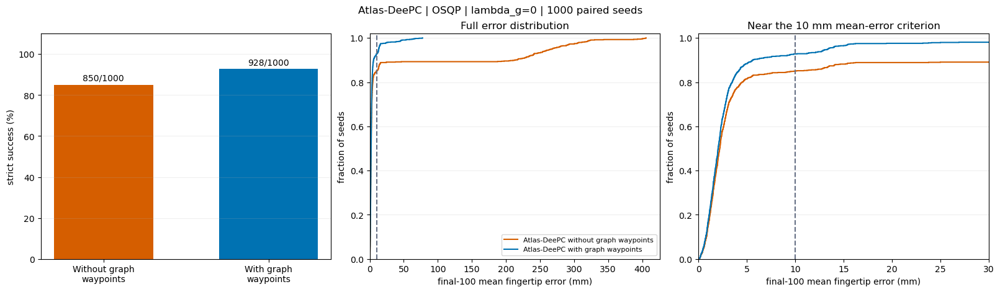

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), constrained_layout=True)
for i, mode in enumerate(METHODS):
    rows = frame[frame['mode'] == mode]
    rate = 100*rows.strict.mean()
    axes[0].bar(i, rate, color=COLORS[mode], width=.6)
    axes[0].text(i, rate+2, f"{rows.strict.sum()}/{len(rows)}", ha="center")
    values = np.sort(rows.mean_error_mm)
    for ax in axes[1:]:
        ax.step(np.r_[0, values], np.r_[0, np.arange(1, len(values)+1)/len(values)],
                where="post", color=COLORS[mode], label=METHODS[mode])
axes[0].set(xticks=[0,1], xticklabels=["Without graph\nwaypoints", "With graph\nwaypoints"],
            ylim=(0,110), ylabel="strict success (%)")
for ax in axes[1:]:
    ax.axvline(10, color="#667085", linestyle="--")
    ax.set(xlim=(0,None), ylim=(0,1.02), xlabel="final-100 mean fingertip error (mm)", ylabel="fraction of seeds")
axes[1].set_title("Full error distribution")
axes[2].set(xlim=(0,30), title="Near the 10 mm mean-error criterion")
axes[1].legend(fontsize=8)
for ax in axes: ax.grid(axis="y", alpha=.2)
fig.suptitle(f"Atlas-DeePC | OSQP | lambda_g=0 | {len(EVALUATION_SEEDS)} paired seeds")
fig.savefig(RESULT_ROOT / "paired_success_and_error.png", dpi=160)
plt.show()


## 4. Computation Time by Module

For fresh local measurements, set `RUN_EVALUATION=True` in the setup cell. This
uses one rollout worker, one numerical thread, a ten-step warm-up, and a new
timestamped output folder. Existing rollout timings are never reused in this mode.
The methods run sequentially, with order alternating across seeds. Stop other
heavy jobs before starting. Only rerunning a plotting cell does not measure time.

The first five steps per rollout are excluded. QP time includes construction,
canonicalization and solve.
Offline SVD, simulator stepping, saving, and video rendering are excluded.

Stacked **means** add to the mean total. Median and P99 module times are shown
separately because percentiles do not add. Terminal-reference selection still
uses graph costs in both methods.

The default saved results came from the earlier four-worker OSQP test, not a new
single-worker benchmark. Its two pilot seeds (222 and 237) used two workers and
are excluded from the timing plots only. Fresh single-worker runs time every
requested seed. The protocol and timed sample count are printed below.

In the no-waypoint variant, the small time recorded under "Graph routing" is
branch/reference bookkeeping, not a waypoint-route search. The common route-cost
terminal selection is timed separately under "Terminal-reference selection".


timing source                      Saved four-worker OSQP experiment; not new loc...
rollout workers                                                                    4
numerical threads per worker                                                       1
excluded two-worker pilot seeds                                           [222, 237]
dtype: object

timed seeds per method       998
timed steps per method    314370
dtype: int64

mean_ms  \
Method                       Atlas-DeePC with graph waypoints   
module                                                          
Chart localization                                     0.0897   
Graph routing                                          0.0086   
Linear subspace retrieval                              0.0010   
Other control-loop work                                0.0451   
QP construction and solve                             79.1396   
Terminal-reference selection                           0.0202   
Total online control                                  79.3043   

                                                                  \
Method                       Atlas-DeePC without graph waypoints   
module                                                             
Chart localization                                        0.0864   
Graph routing                                             0.0058   
Linear subspace retrieval                                 0.0009   
Other control-loop work                                   0.0444   
QP construction and solve                                80.0292   
Terminal-reference selection                              0.0196   
Total online control                                     80.1863   

                                                    median_ms  \
Method                       Atlas-DeePC with graph waypoints   
module                                                          
Chart localization                                     0.0696   
Graph routing                                          0.0063   
Linear subspace retrieval                              0.0007   
Other control-loop work                                0.0337   
QP construction and solve                             68.3302   
Terminal-reference selection                           0.0153   
Total online control                                  68.4717   

                                                                  \
Method                       Atlas-DeePC without graph waypoints   
module                                                             
Chart localization                                        0.0697   
Graph routing                                             0.0043   
Linear subspace retrieval                                 0.0007   
Other control-loop work                                   0.0335   
QP construction and solve                                69.2851   
Terminal-reference selection                              0.0153   
Total online control                                     69.4238   

                                                       p99_ms  \
Method                       Atlas-DeePC with graph waypoints   
module                                                          
Chart localization                                     0.3806   
Graph routing                                          0.0261   
Linear subspace retrieval                              0.0020   
Other control-loop work                                0.1980   
QP construction and solve                            292.4116   
Terminal-reference selection                           0.0733   
Total online control                                 292.7639   

                                                                  
Method                       Atlas-DeePC without graph waypoints  
module                                                            
Chart localization                                        0.3751  
Graph routing                                             0.0168  
Linear subspace retrieval                                 0.0020  
Other control-loop work                                   0.1895  
QP construction and solve                               281.4862  
Terminal-reference selection                              0.0738  
Total online control                                    281.7779

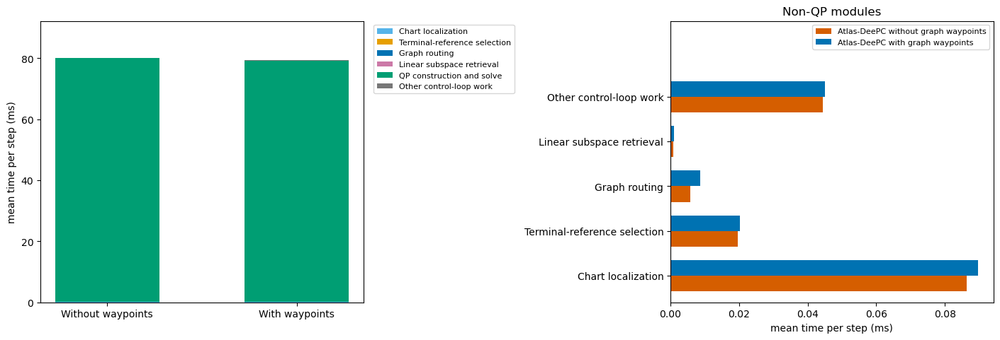

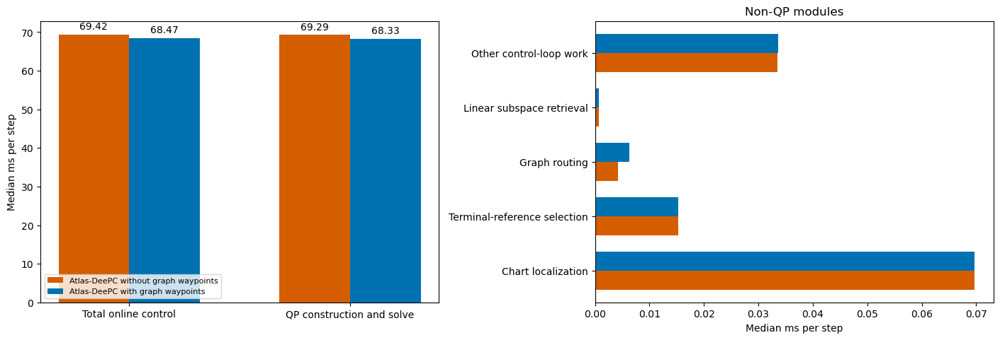

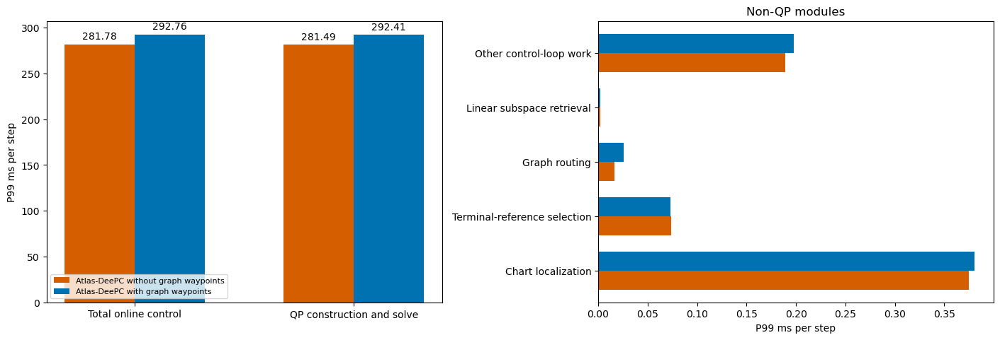

,Atlas-DeePC without graph waypoints,Atlas-DeePC with graph waypoints
One-time candidate setup (ms),,
mean,6.816569,6.697121
median,5.414229,5.360500
p95,9.977606,9.018296


In [8]:
from baseline_1000_benchmark import summarize_timing
protocol = payload.get("benchmark_protocol")
if protocol is not None:
    assert protocol["kind"] == "fresh_single_worker_osqp"
    assert protocol["workers"] == protocol["numerical_threads"] == 1
    assert protocol["reused_rollouts"] == 0
    TIMING_SEEDS = EVALUATION_SEEDS
    display(pd.Series(protocol, name="Fresh local benchmark protocol"))
else:
    TIMING_SEEDS = [s for s in EVALUATION_SEEDS if s not in {222,237}]
    display(pd.Series({"timing source":"Saved four-worker OSQP experiment; not new local measurements",
        "rollout workers":payload["workers"], "numerical threads per worker":payload["numerical_threads"],
        "excluded two-worker pilot seeds":str(sorted(set(EVALUATION_SEEDS)&{222,237}))}))
assert TIMING_SEEDS, "Select non-pilot seeds or collect a fresh local benchmark."
display(pd.Series({"timed seeds per method":len(TIMING_SEEDS),
                   "timed steps per method":len(TIMING_SEEDS)*(config.steps-5)}))
timings = {mode:summarize_timing([RESULT_ROOT/mode/f"seed{s}_control_results.npz" for s in TIMING_SEEDS]) for mode in METHODS}
assert all(t["timed_steps"] == len(TIMING_SEEDS)*(config.steps-5) for t in timings.values())
timing = pd.DataFrame([{"mode": mode, "Method": METHODS[mode], **entry}
    for mode, data in timings.items() for entry in data["modules"]])
display(timing.pivot(index="module", columns="Method", values=["mean_ms", "median_ms", "p99_ms"]).round(4))
module_names = [x for x in timing.module.unique() if x != "Total online control"]
palette = ["#56B4E9", "#E69F00", "#0072B2", "#CC79A7", "#009E73", "#777777"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.7), constrained_layout=True)
bottom = np.zeros(2)
for name, color in zip(module_names, palette):
    values = np.array([timing.loc[(timing['mode']==mode)&(timing.module==name), "mean_ms"].item() for mode in METHODS])
    axes[0].bar([0,1], values, bottom=bottom, color=color, label=name, width=.55)
    bottom += values
axes[0].set(xticks=[0,1], xticklabels=["Without waypoints", "With waypoints"], ylim=(0,bottom.max()*1.15), ylabel="mean time per step (ms)")
axes[0].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.02,1))
overhead = [name for name in module_names if name != "QP construction and solve"]
y = np.arange(len(overhead))
for i, mode in enumerate(METHODS):
    values = [timing.loc[(timing['mode']==mode)&(timing.module==name), "mean_ms"].item() for name in overhead]
    axes[1].barh(y+(i-.5)*.35, values, height=.35, color=COLORS[mode], label=METHODS[mode])
axes[1].set(yticks=y, yticklabels=overhead, xlabel="mean time per step (ms)", title="Non-QP modules")
axes[1].set_ylim(-.6, len(overhead)+.7)
axes[1].legend(fontsize=8, loc="upper right")
fig.savefig(RESULT_ROOT/"paired_module_mean_times.png", dpi=160)
plt.show()
for statistic, label in [("median_ms","Median"),("p99_ms","P99")]:
    fig, axes = plt.subplots(1,2,figsize=(14,4.7),constrained_layout=True)
    for i, mode in enumerate(METHODS):
        values = [timing.loc[(timing['mode']==mode)&(timing.module==name), statistic].item() for name in ("Total online control","QP construction and solve")]
        bars = axes[0].bar(np.arange(2)+(i-.5)*.32,values,width=.32,color=COLORS[mode],label=METHODS[mode])
        axes[0].bar_label(bars,fmt="%.2f",padding=3)
        values = [timing.loc[(timing['mode']==mode)&(timing.module==name), statistic].item() for name in overhead]
        axes[1].barh(y+(i-.5)*.35,values,height=.35,color=COLORS[mode])
    axes[0].set(xticks=[0,1],xticklabels=["Total online control","QP construction and solve"],ylabel=f"{label} ms per step")
    axes[0].set_ylim(bottom=0)
    axes[0].margins(y=.2)
    axes[0].legend(fontsize=8)
    axes[1].set(yticks=y,yticklabels=overhead,xlabel=f"{label} ms per step",title="Non-QP modules")
    fig.savefig(RESULT_ROOT/f"paired_module_{statistic}.png",dpi=160)
    plt.show()
display(pd.DataFrame({METHODS[mode]: data["one_time_goal_setup_ms"] for mode,data in timings.items()}).rename_axis("One-time candidate setup (ms)"))


## 5. Paired Rollout Videos

Each pair uses the same seed and target. Videos replay saved actions, with measured
outputs checked against the numerical traces. Outcome labels use the complete
320-step run, not the displayed video duration. These selected examples are
diagnostic illustrations; the full evaluation above determines the success rate.


In [9]:
import base64
from baseline_waypoint_media import prepare_media, GALLERY_SEEDS, DASHBOARD_SEEDS
from render_routed_deepc_dashboard import file_sha256
PREPARE_MEDIA = RUN_EVALUATION
if PREPARE_MEDIA:
    prepare_media(RESULT_ROOT, expected_solver=SOLVER, seeds=EVALUATION_SEEDS)
MEDIA_DIR = RESULT_ROOT / "videos"
def media_uri(path, mime):
    return "data:"+mime+";base64,"+base64.b64encode(Path(path).read_bytes()).decode("ascii")
def show_pair(seed, dashboard=False):
    cards = []
    for mode in METHODS:
        row = rows_by_mode[mode][seed]
        name = f"{mode}_seed{seed}" + ("_025x" if dashboard else "_replay")
        video = MEDIA_DIR / (name+".mp4")
        metadata = json.loads((MEDIA_DIR/(name+".json")).read_text())
        trace_path = RESULT_ROOT/mode/f"seed{seed}_control_results.npz"
        assert metadata["source_result_sha256"] == file_sha256(trace_path)
        assert metadata["lam_g"] == 0 and metadata["reference_mode"] == mode
        assert metadata["solver"] == SOLVER == "OSQP"
        success = bool(row["success_30"] and row["success_100"])
        status = "STRICT SUCCESS" if success else "STRICT FAILURE"
        color = "#166534" if success else "#b91c1c"
        poster = ""
        detail = f"Final-100 mean: {1000*row['mean_last_100']:.3f} mm | OSQP | lambda_g=0"
        if dashboard:
            assert metadata["play_speed"] == .25
            assert metadata["dashboard_renderer_sha256"] == file_sha256(ROOT/"src/render_routed_deepc_dashboard.py")
            detail += f" | 0.25x | {metadata['displayed_control_steps']}/{metadata['saved_control_steps']} steps shown"
            poster_path = MEDIA_DIR/(name+"_poster.png")
            poster = f' poster="{media_uri(poster_path, "image/png")}"'
        else:
            assert metadata["maximum_replay_output_error"] <= 1e-8
        cards.append(f'<div style="background:#fff;color:#111827;padding:10px;border:1px solid #d1d5db;min-width:0">'
            f'<h4 style="margin:0 0 6px">Seed {seed}: {METHODS[mode]}</h4>'
            f'<p style="margin:0 0 8px;color:{color}">{status}</p><p style="font-size:12px">{detail}</p>'
            f'<video controls preload="metadata"{poster} src="{media_uri(video,"video/mp4")}" style="width:100%;display:block"></video></div>')
    display(HTML('<div style="display:grid;grid-template-columns:repeat(auto-fit,minmax(min(480px,100%),1fr));gap:12px;margin-bottom:16px">'+''.join(cards)+'</div>'))
for seed in GALLERY_SEEDS:
    if seed in EVALUATION_SEEDS:
        show_pair(seed)


## 6. Slowed Control and Chart Diagnostics

The 0.25x dashboards show the arm, DeePC prediction, active reference, measured
charts, true fingertip error, and inputs. A successful rollout may have its settled
tail omitted for display only; failures retain the full rollout so late drift is
visible. Playback speed follows the existing dashboard convention (20 control
samples per second at 1x), not a claim about real-time solver execution.



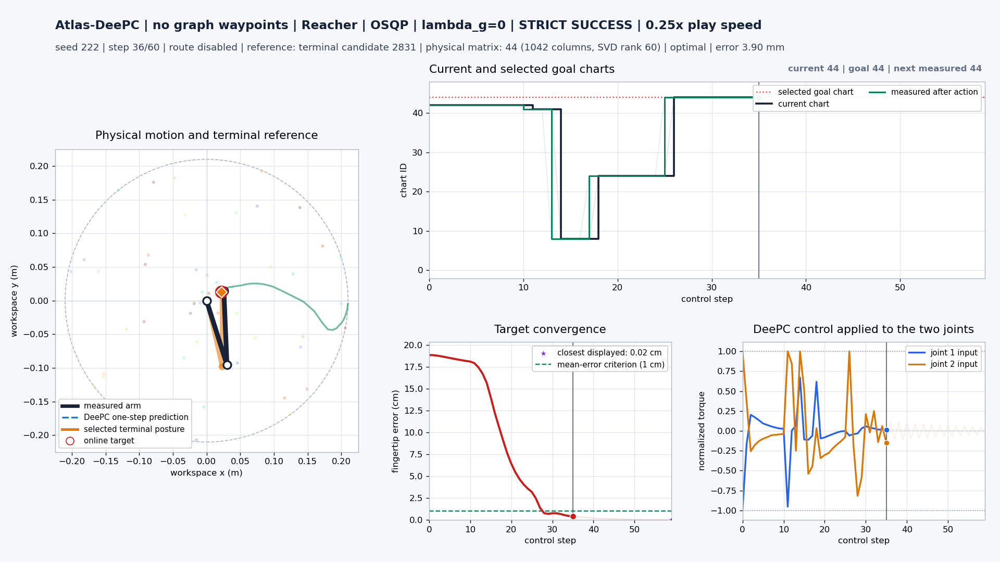
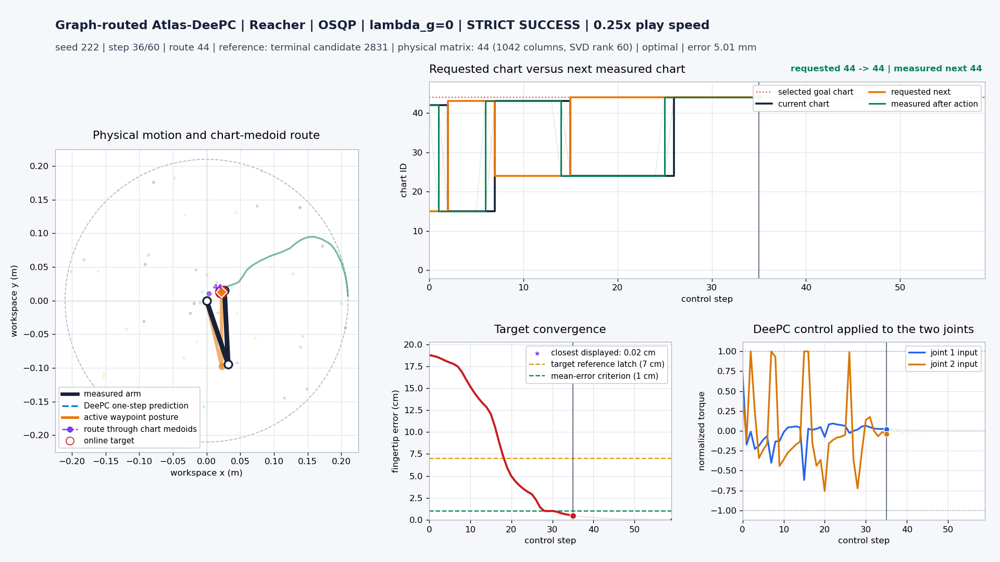


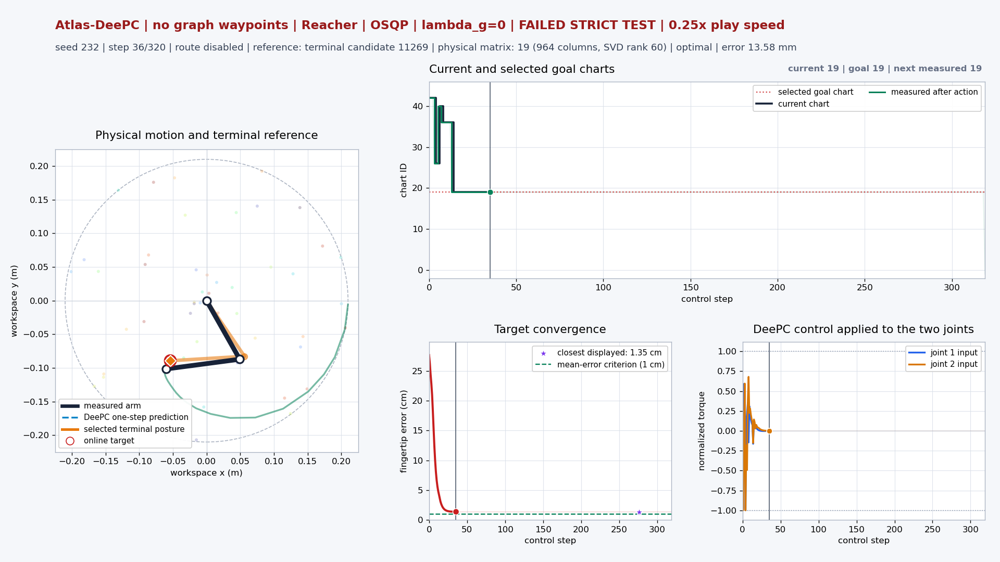
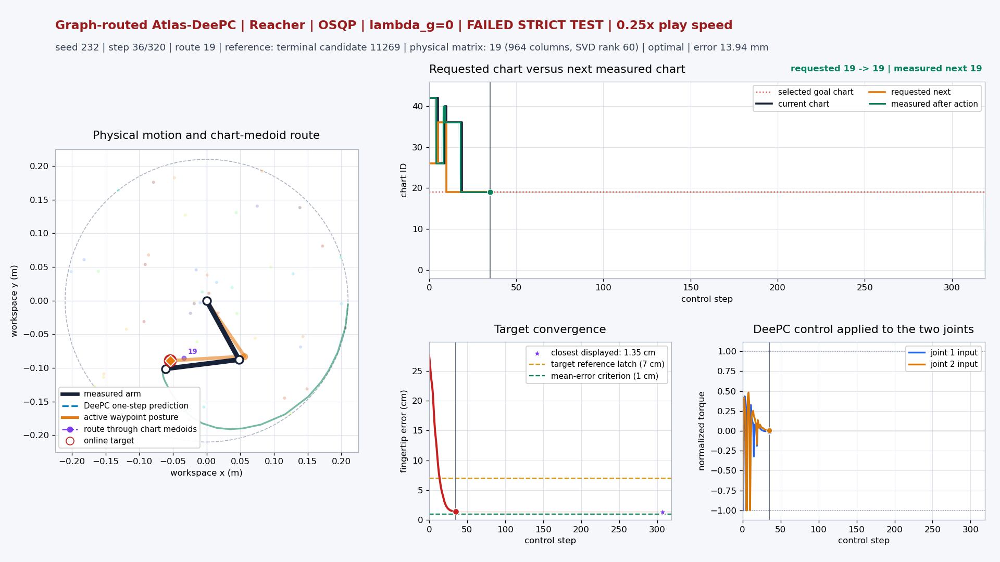


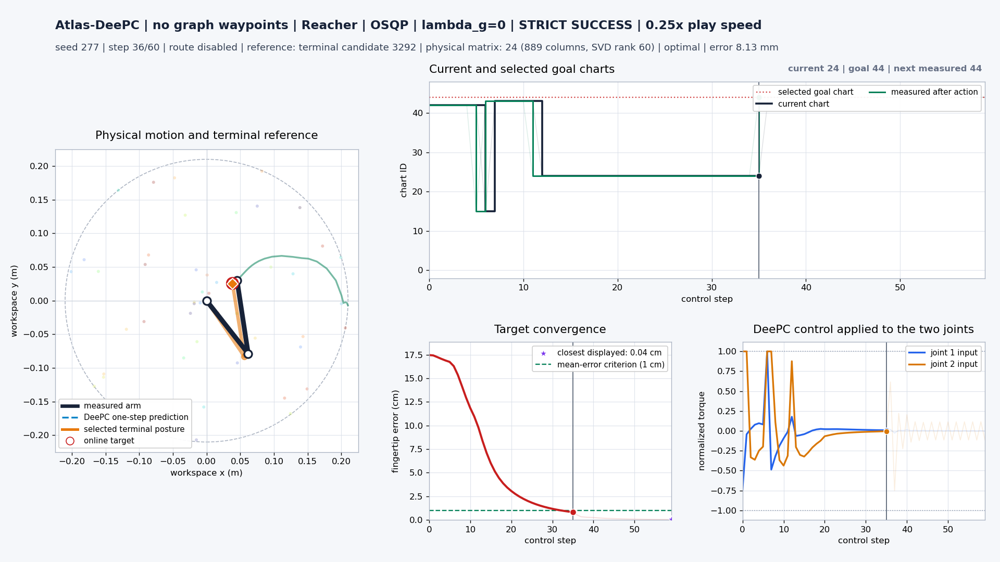
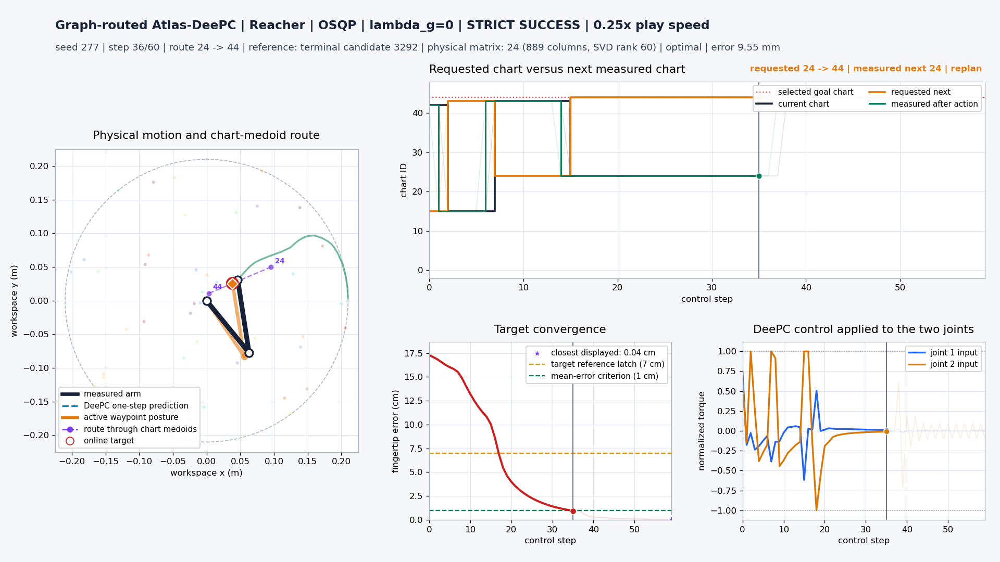

In [10]:
for seed in DASHBOARD_SEEDS:
    if seed in EVALUATION_SEEDS:
        show_pair(seed, dashboard=True)


## 7. Reproduction and Version Boundary

Edit `EVALUATION_SEEDS` and set `RUN_EVALUATION=True` to measure both OSQP methods
on this computer. Keep `WORKERS=1`. Every execution of the setup cell in this mode
starts a fresh timestamped run; it does not resume old timings. The ten-step
warm-up is excluded from outcomes. Keep the computer awake and avoid other heavy
jobs during the run. Video rendering happens after all rollout measurements.

With `RUN_EVALUATION=False`, the notebook shows the completed 1,000-seed OSQP
experiment and its saved shared-computer timings. It does not rerun control.
`PREPARE_MEDIA` can regenerate OSQP videos from the corresponding saved traces.

The notebook routes execution through `baseline_osqp_benchmark.run_fresh_panel`
and `baseline_osqp_comparison`, which enforce OSQP without changing the QP.
Historical low-level controller code and experiment caches are preserved for
reproducibility; no old video or timing is relabeled as a new run.

The earlier comparison is retained in
`archive/notebooks/baseline_clarabel_osqp_solver_comparison.ipynb`.
The separate comparison notebooks and rank ablations are not changed here.
